In [1]:
import pandas as pd
df = pd.read_csv('preprocessed.csv')
print(f"Loaded {len(df)} documents")

Loaded 89663 documents


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
 
df_fake = df[df['class_label'] == False]
df_real = df[df['class_label'] == True]
 
print(f"Total documents: {len(df)}")
print(f"Fake posts: {len(df_fake)} ({len(df_fake)/len(df)*100:.1f}%)")
print(f"Real posts: {len(df_real)} ({len(df_real)/len(df)*100:.1f}%)")
 
texts = df['cleaned_post'].tolist()
print(f"\nSample cleaned post: {texts[0]}")

Total documents: 89663
Fake posts: 51863 (57.8%)
Real posts: 37800 (42.2%)

Sample cleaned post: @potus biden blunders 6 month update inflation delta mismanagement covid kid abandon americans afghanistan arm taliban s. border crisis break job growth abuse power exec orders $ 3.5 t reconciliation eviction moratorium) miss


In [3]:
from sklearn.feature_extraction.text import CountVectorizer
 
# min_df=5 removes rare terms, max_df=0.90 removes terms in >90% of docs (near-stopwords)
bow_vectorizer = CountVectorizer(min_df=5, max_df=0.90)
X_bow = bow_vectorizer.fit_transform(texts)
bow_vocab = bow_vectorizer.get_feature_names_out()
 
print(f"BoW matrix shape: {X_bow.shape}")
print(f"Vocabulary size: {len(bow_vocab)}")

BoW matrix shape: (89663, 15773)
Vocabulary size: 15773


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
 
tfidf_topic_vect = TfidfVectorizer(min_df=5, max_df=0.90)
X_tfidf_topic = tfidf_topic_vect.fit_transform(texts)
tfidf_vocab = tfidf_topic_vect.get_feature_names_out()
 
print(f"TF-IDF matrix shape: {X_tfidf_topic.shape}")
print(f"Vocabulary size: {len(tfidf_vocab)}")

TF-IDF matrix shape: (89663, 15773)
Vocabulary size: 15773


In [5]:
from sklearn.decomposition import LatentDirichletAllocation
 
N_TOPICS = 10  # number of topics to discover
 
print("Fitting LDA model...")
lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS,
    max_iter=20,
    learning_method='online',   # online = faster for large datasets
    random_state=1,
    n_jobs=-1
)
lda_topics = lda_model.fit_transform(X_bow)
print(f"LDA perplexity: {lda_model.perplexity(X_bow):.2f}")

Fitting LDA model...
LDA perplexity: 3174.25


In [7]:
def display_topics(model, vocab, n_top_words=10, model_name="LDA"):
    print(f"\n=== {model_name} Topics ===")
    topics = {}
    for topic_idx, topic in enumerate(model.components_):
        top_words = [vocab[i] for i in topic.argsort()[:-n_top_words - 1:-1]]
        topics[f"Topic {topic_idx+1}"] = top_words
        print(f"Topic {topic_idx+1}: {', '.join(top_words)}")
    return topics
 
lda_topic_words = display_topics(lda_model, bow_vocab, model_name="LDA (BoW)")


=== LDA (BoW) Topics ===
Topic 1: obama, fact, car, hand, majority, office, food, middle, gun, ceo
Topic 2: white, like, not, look, cause, vaccine, test, say, know, antifa
Topic 3: job, million, year, 000, high, harris, time, low, income, woman
Topic 4: people, not, go, voter, amp, child, know, want, like, mask
Topic 5: black, man, racist, city, african, record, racism, crime, baby, access
Topic 6: tax, vaccine, year, taxis, rate, pay, covid, raise, wage, 19
Topic 7: vote, election, state, ballot, fraud, michigan, long, georgia, 99, see
Topic 8: covid, death, die, texas, drug, abortion, arizona, pelosi, news, 19
Topic 9: fauci, happen, audit, united, free, states, cnn, video, dr, read
Topic 10: trump, biden, joe, president, border, lie, realdonaldtrump, administration, say, call


In [8]:
from sklearn.decomposition import NMF
 
print("Fitting NMF model...")
nmf_model = NMF(
    n_components=N_TOPICS,
    random_state=1,
    max_iter=400
)
nmf_topics = nmf_model.fit_transform(X_tfidf_topic)
print(f"NMF reconstruction error: {nmf_model.reconstruction_err_:.2f}")
#lower reconstruction error means a better fit
 
nmf_topic_words = display_topics(nmf_model, tfidf_vocab, model_name="NMF (TF-IDF)")

Fitting NMF model...
NMF reconstruction error: 292.76

=== NMF (TF-IDF) Topics ===
Topic 1: trump, obama, white, job, amp, black, administration, president, million, donald
Topic 2: vaccine, recover, approve, china, pfizer, covid, fda, zombie, dmx, legend
Topic 3: tax, high, rate, pay, taxis, income, raise, americans, nation, cut
Topic 4: vote, election, ballot, voter, fraud, state, michigan, count, audit, arizona
Topic 5: biden, joe, harris, say, kamala, president, raise, americans, border, want
Topic 6: 99, age, rate, survival, 19, 98, 94, 997, 49, 69
Topic 7: wage, minimum, year, inflation, 50, 15, support, federal, increase, majority
Topic 8: madison, sign, declaration, independence, james, not, cawthornfornc, know, history, 25
Topic 9: mask, wear, vaccinate, not, science, fauci, believe, people, dr, march
Topic 10: covid, die, death, people, overdose, drug, test, 19, doctor, case


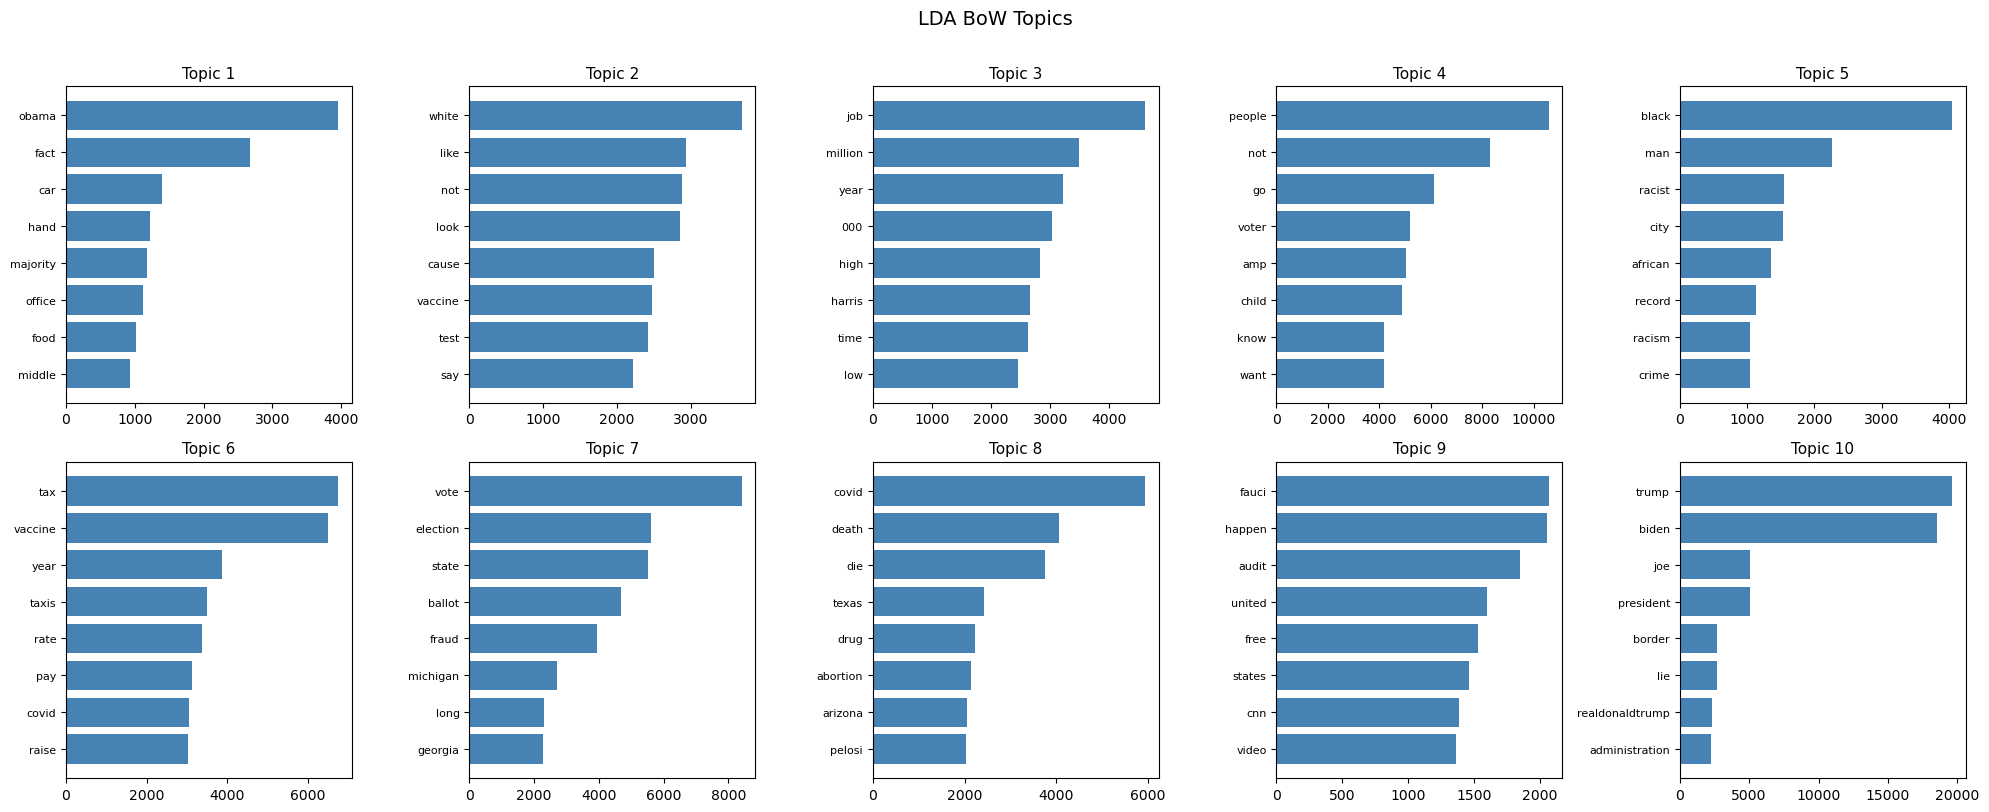

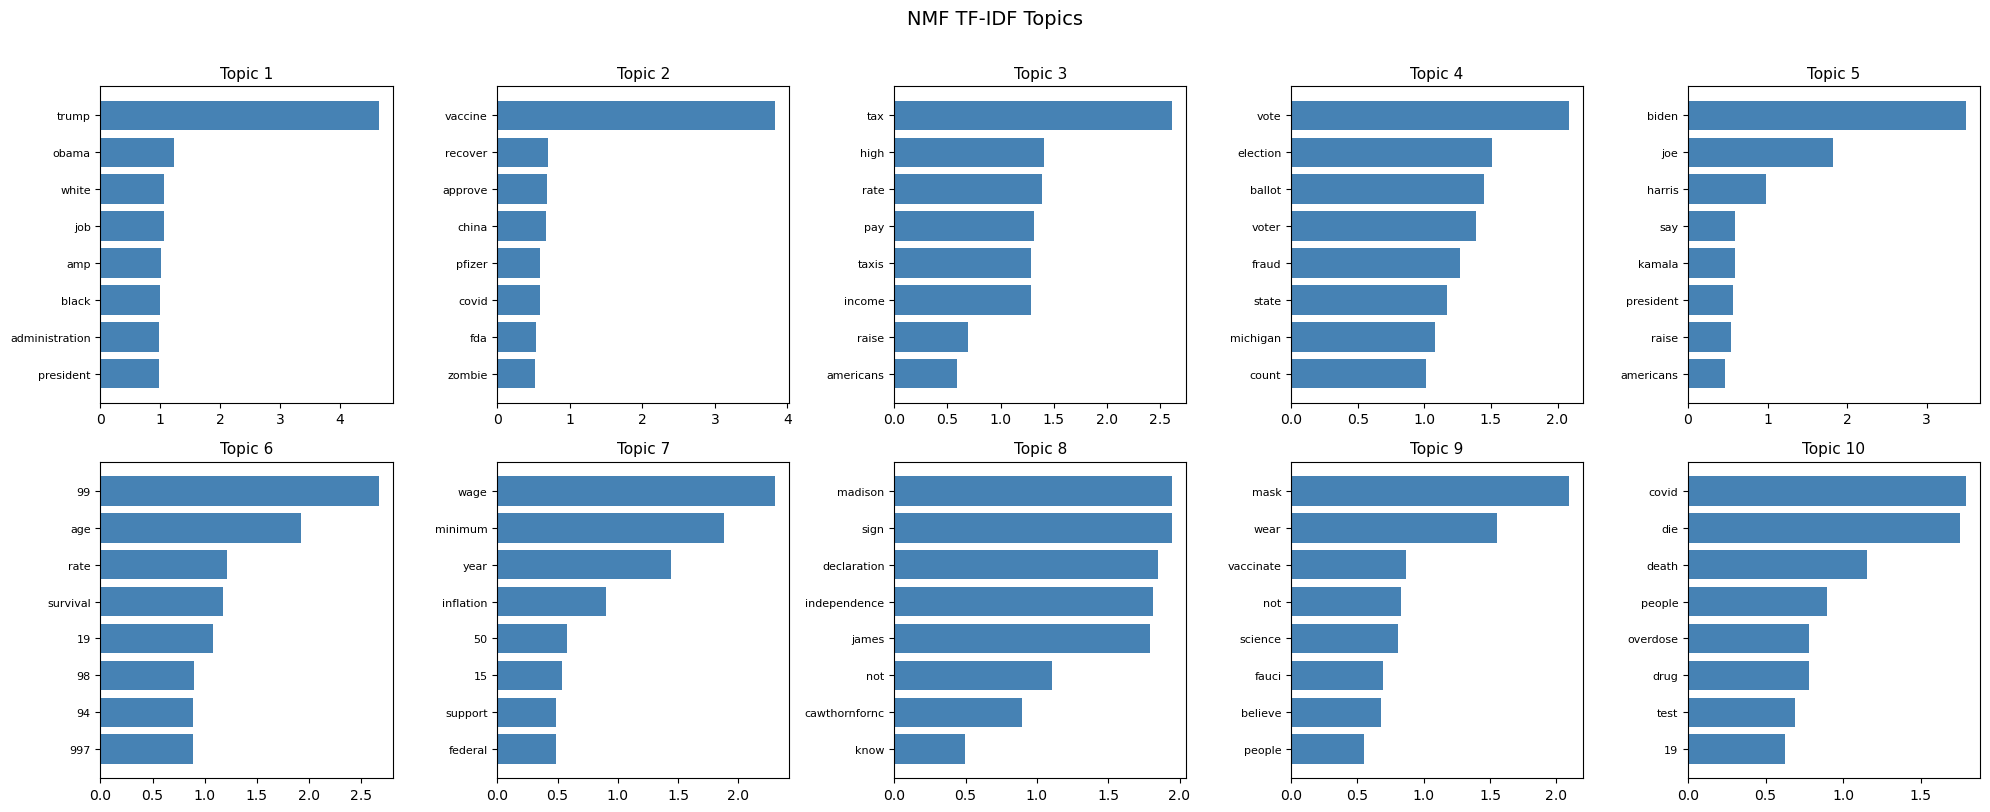

In [9]:
def plot_top_words(model, vocab, n_top_words=8, title="Topic Model"):
    fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=False)
    axes = axes.flatten()
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[:-n_top_words - 1:-1]
        top_words   = [vocab[i] for i in top_indices]
        top_weights = [topic[i] for i in top_indices]
        axes[topic_idx].barh(top_words[::-1], top_weights[::-1], color='steelblue')
        axes[topic_idx].set_title(f'Topic {topic_idx + 1}', fontsize=11)
        axes[topic_idx].tick_params(axis='y', labelsize=8)
    fig.suptitle(title, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(f"{title.replace(' ', '_')}_topics.png", dpi=150, bbox_inches='tight')
    plt.show()
 
plot_top_words(lda_model, bow_vocab, title="LDA BoW Topics")
plot_top_words(nmf_model, tfidf_vocab, title="NMF TF-IDF Topics")

In [10]:
def topic_class_analysis(topic_matrix, model_name, labels):
    """
    For each topic, calculates what % of documents assigned to it
    are fake vs real — reveals whether topics are class-specific
    """
    dominant_topics = topic_matrix.argmax(axis=1)
    df_analysis = pd.DataFrame({
        'dominant_topic': dominant_topics,
        'class_label': labels.values
    })
 
    print(f"\n {model_name} — Topic-Class Distribution")
    print(f"{'Topic':<10} {'Total':>8} {'Fake %':>10} {'Real %':>10} {'Bias':>12}")
    print("-" * 52)
 
    results = []
    for topic_idx in range(topic_matrix.shape[1]):
        subset = df_analysis[df_analysis['dominant_topic'] == topic_idx]
        total  = len(subset)
        if total == 0:
            continue
        fake_pct = (subset['class_label'] == False).sum() / total * 100
        real_pct = (subset['class_label'] == True).sum()  / total * 100
        bias = 'FAKE-heavy' if fake_pct > 60 else ('REAL-heavy' if real_pct > 60 else 'Balanced')
        print(f"Topic {topic_idx+1:<4} {total:>8} {fake_pct:>9.1f}% {real_pct:>9.1f}% {bias:>12}")
        results.append({'topic': topic_idx+1, 'total': total,
                        'fake_pct': fake_pct, 'real_pct': real_pct})
    return pd.DataFrame(results)
 
lda_class_df  = topic_class_analysis(lda_topics,  "LDA",  df['class_label'])
nmf_class_df  = topic_class_analysis(nmf_topics,  "NMF",  df['class_label'])


 LDA — Topic-Class Distribution
Topic         Total     Fake %     Real %         Bias
----------------------------------------------------
Topic 1        2001      35.7%      64.3%   REAL-heavy
Topic 2        8351      67.7%      32.3%   FAKE-heavy
Topic 3       10526      40.3%      59.7%     Balanced
Topic 4       31103      59.0%      41.0%     Balanced
Topic 5        3283      35.5%      64.5%   REAL-heavy
Topic 6       10741      58.4%      41.6%     Balanced
Topic 7        6701      73.2%      26.8%   FAKE-heavy
Topic 8        4505      60.5%      39.5%   FAKE-heavy
Topic 9        3057      59.3%      40.7%     Balanced
Topic 10       9395      64.3%      35.7%   FAKE-heavy

 NMF — Topic-Class Distribution
Topic         Total     Fake %     Real %         Bias
----------------------------------------------------
Topic 1       17023      44.2%      55.8%     Balanced
Topic 2        7350      85.6%      14.4%   FAKE-heavy
Topic 3        8934      30.8%      69.2%   REAL-heavy
Top

In [11]:
def topic_headline_analysis(topic_matrix, model_name, n_examples=3):
    """
    For each topic, finds the documents with the highest topic weight
    and displays their associated news headlines
    """
    print(f"\n=== {model_name} — Top Headlines per Topic ===")
    for topic_idx in range(topic_matrix.shape[1]):
        top_doc_indices = topic_matrix[:, topic_idx].argsort()[-n_examples:][::-1]
        print(f"\nTopic {topic_idx+1}:")
        for idx in top_doc_indices:
            headline = df.iloc[idx]['news_headline'][:80]
            label    = df.iloc[idx]['class_label']
            weight   = topic_matrix[idx, topic_idx]
            print(f"  [{label}] (weight={weight:.3f}) {headline}")
 
topic_headline_analysis(lda_topics, "LDA")
topic_headline_analysis(nmf_topics, "NMF")


=== LDA — Top Headlines per Topic ===

Topic 1:
  [False] (weight=0.968) The mRNA COVID-19 vaccines are really gene therapy.
  [False] (weight=0.968) The mRNA COVID-19 vaccines are really gene therapy.
  [False] (weight=0.968) The mRNA COVID-19 vaccines are really gene therapy.

Topic 2:
  [False] (weight=0.900) Most of the wildfires on the West Coast are all being started by antifa.
  [False] (weight=0.768) Elderly people were beat up by a BLM hate group for being white.
  [True] (weight=0.762) "Twitter is banned in Iran."

Topic 3:
  [False] (weight=0.964) End of eviction moratorium means millions of Americans could lose their housing 
  [True] (weight=0.964) End of eviction moratorium means millions of Americans could lose their housing 
  [True] (weight=0.964) End of eviction moratorium means millions of Americans could lose their housing 

Topic 4:
  [True] (weight=0.936) "A shocking 20 veterans are committing suicide each and every day, especially ou
  [False] (weight=0.925) Mor

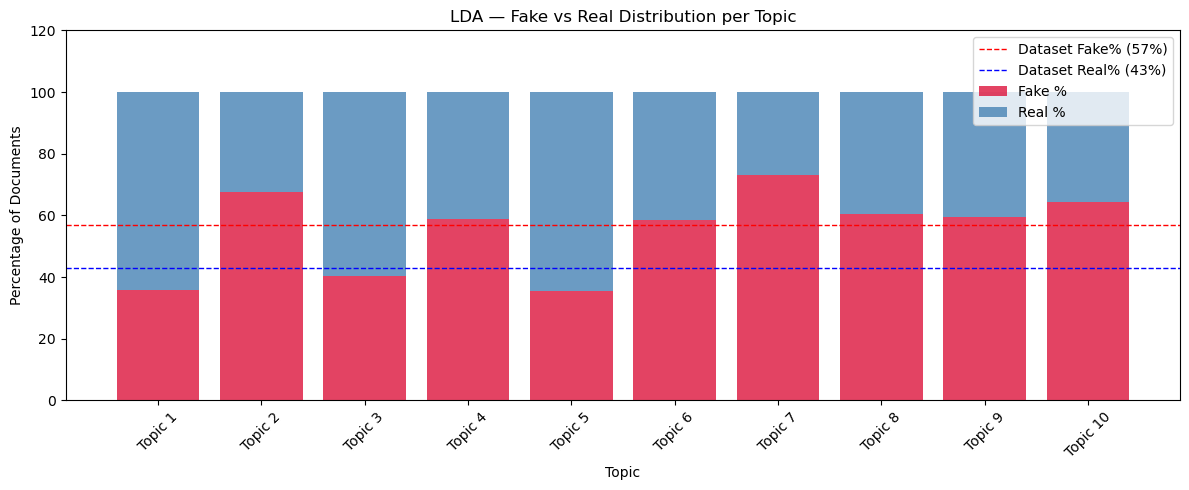

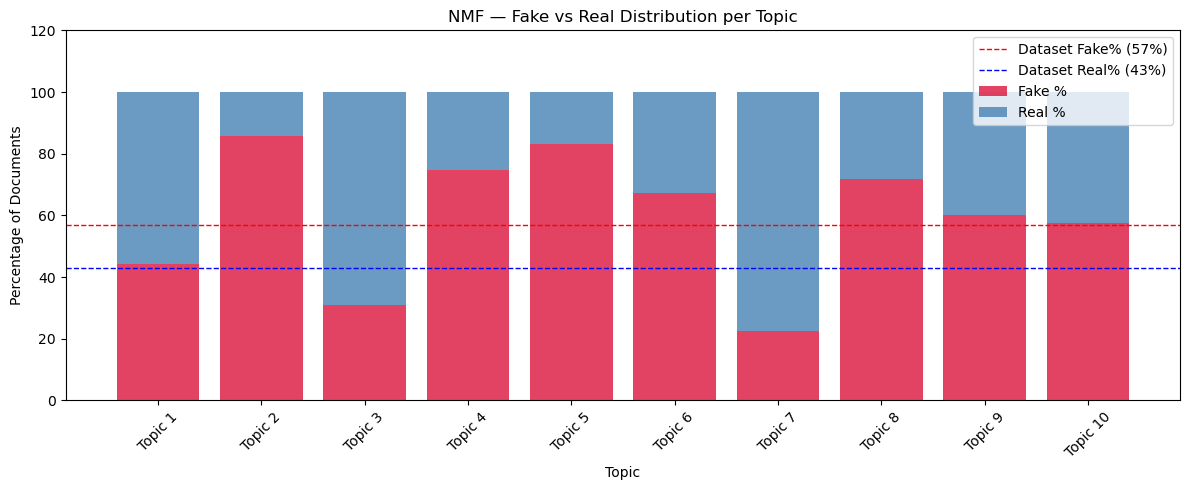

In [12]:
def plot_topic_class_bias(class_df, model_name):
    fig, ax = plt.subplots(figsize=(12, 5))
    x = [f"Topic {t}" for t in class_df['topic']]
    ax.bar(x, class_df['fake_pct'], label='Fake %', color='crimson',  alpha=0.8)
    ax.bar(x, class_df['real_pct'], label='Real %', color='steelblue', alpha=0.8,
           bottom=class_df['fake_pct'])
    ax.axhline(57, color='red',  linestyle='--', linewidth=1, label='Dataset Fake% (57%)')
    ax.axhline(43, color='blue', linestyle='--', linewidth=1, label='Dataset Real% (43%)')
    ax.set_title(f'{model_name} — Fake vs Real Distribution per Topic')
    ax.set_ylabel('Percentage of Documents')
    ax.set_xlabel('Topic')
    ax.legend(loc='upper right')
    ax.set_ylim(0, 120)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"{model_name}_topic_class_bias.png", dpi=150)
    plt.show()
 
plot_topic_class_bias(lda_class_df, "LDA")
plot_topic_class_bias(nmf_class_df, "NMF")

In [13]:
print("Model Comparison")
print(f"LDA perplexity (lower=better):         {lda_model.perplexity(X_bow):.2f}")
print(f"NMF reconstruction error (lower=better): {nmf_model.reconstruction_err_:.2f}")
print("\nInterpretation: NMF on TF-IDF typically produces more interpretable")
print("topics for short social media text; LDA suits longer documents.")

Model Comparison
LDA perplexity (lower=better):         3174.25
NMF reconstruction error (lower=better): 292.76

Interpretation: NMF on TF-IDF typically produces more interpretable
topics for short social media text; LDA suits longer documents.


Tuning LDA: number of topics
  n_topics=5 -> perplexity=2566.41
  n_topics=10 -> perplexity=3205.24
  n_topics=15 -> perplexity=3680.10
  n_topics=20 -> perplexity=4112.08


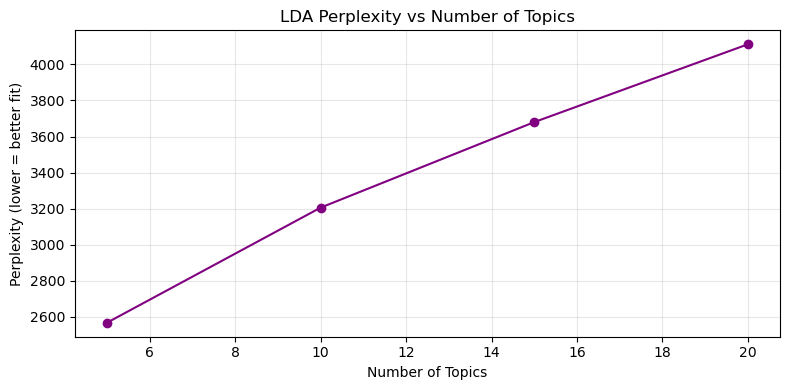

In [14]:
print("Tuning LDA: number of topics")
perplexity_scores = []
topic_range = [5, 10, 15, 20]
 
for n in topic_range:
    lda_test = LatentDirichletAllocation(
        n_components=n, max_iter=10,
        learning_method='online', random_state=1, n_jobs=-1
    )
    lda_test.fit(X_bow)
    perp = lda_test.perplexity(X_bow)
    print(f"  n_topics={n} -> perplexity={perp:.2f}")
    perplexity_scores.append(perp)
    del lda_test
 
plt.figure(figsize=(8, 4))
plt.plot(topic_range, perplexity_scores, marker='o', color='purple')
plt.title('LDA Perplexity vs Number of Topics')
plt.xlabel('Number of Topics')
plt.ylabel('Perplexity (lower = better fit)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lda_perplexity_tuning.png', dpi=150)
plt.show()

In [15]:
import pickle
 
with open('lda_best_model.pkl', 'wb') as f:
    pickle.dump(lda_model, f)
with open('nmf_best_model.pkl', 'wb') as f:
    pickle.dump(nmf_model, f)
with open('bow_vectorizer_topic.pkl', 'wb') as f:
    pickle.dump(bow_vectorizer, f)
with open('tfidf_topic_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf_topic_vect, f)
 
print("Saved: lda_best_model.pkl, nmf_best_model.pkl")
print("Saved: bow_vectorizer_topic.pkl, tfidf_topic_vectorizer.pkl")

Saved: lda_best_model.pkl, nmf_best_model.pkl
Saved: bow_vectorizer_topic.pkl, tfidf_topic_vectorizer.pkl
